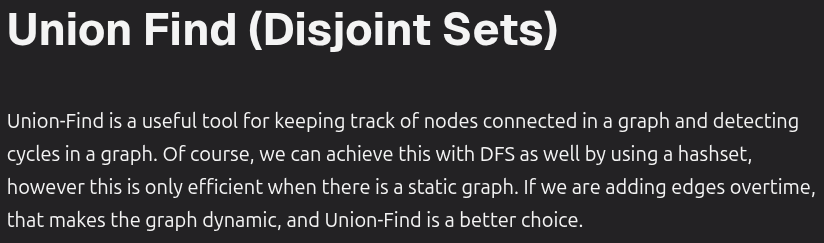

![](./drawings/disjoint_set_union_find.svg)

In [ ]:
class UnionFind:
    
    def __init__(self, n: int):
        self.nodeToParentMap = dict()
        self.nodeToSubTreeHeightMap = dict()

        for node in range(n):
            self.nodeToParentMap[node] = node
            self.nodeToSubTreeHeightMap[node] = 0

        self.numberOfConnectedComponents = n

    def find(self, x: int) -> int:
        currentNode = x
        while currentNode != self.nodeToParentMap[currentNode]:
            currentNodeParent = self.nodeToParentMap[currentNode]
            currentNodeGrandparent = self.nodeToParentMap[currentNodeParent]

            self.nodeToParentMap[currentNode] = currentNodeGrandparent
            currentNode = currentNodeParent
        return currentNode

    def isSameComponent(self, x: int, y: int) -> bool:
        return self.find(x) == self.find(y)

    def union(self, x: int, y: int) -> bool:
        rootX = self.find(x)
        rootY = self.find(y)

        if rootX == rootY:
            return False

        subTreeHeightX = self.nodeToSubTreeHeightMap[rootX]
        subTreeHeightY = self.nodeToSubTreeHeightMap[rootY]
        if subTreeHeightX > subTreeHeightY:
            self.nodeToParentMap[rootY] = rootX
        elif subTreeHeightX < subTreeHeightY:
            self.nodeToParentMap[rootX] = rootY
        else:
            self.nodeToParentMap[rootY] = rootX
            self.nodeToSubTreeHeightMap[rootX] += 1

        self.numberOfConnectedComponents -= 1
        
        return True

    def getNumComponents(self) -> int:
        return self.numberOfConnectedComponents

In [ ]:
class UnionFind:
    def __init__(self, n: int):
        self.parent = [i for i in range(n)]
        self.size = [1] * n
        self.num_components = n

    def find(self, x: int) -> int:
        # Finds the root of x
        if x != self.parent[x]:
            self.parent[x] = self.find(self.parent[x])
        return self.parent[x]

    def isSameComponent(self, x: int, y: int) -> bool:
        return self.find(x) == self.find(y)

    def union(self, x: int, y: int) -> bool:
        # Connects x and y
        root_x = self.find(x)
        root_y = self.find(y)
        if root_x != root_y:
            if self.size[root_x] < self.size[root_y]:
                self.parent[root_x] = root_y
                self.size[root_y] += self.size[root_x]
            else:
                self.parent[root_y] = root_x
                self.size[root_x] += self.size[root_y]
            self.num_components -= 1
            return True
        return False

    def getNumComponents(self) -> int:
        return self.num_components